# DỰ ÁN HỌC MÁY (MACHINE LEARNING) - NLP-01
# BÁO CÁO TIẾN ĐỘ THỰC HIỆN TỪ KAN-1 ĐẾN KAN-8
## Đề tài: Phân tích quan điểm phản hồi của người dùng về ứng dụng di động
**Giảng viên hướng dẫn:** ThS. Hà Thị Thanh  
**Nhóm thực hiện:** Nhóm 12  
* Lê Hồng Sơn (Nhóm trưởng)
* Lưu Thị Khánh Ly
* Ngô Thị Sinh
* Nguyễn Thanh Tùng

---

1. **Phần I (KAN-1 -> KAN-5):** Thu thập dữ liệu thô, Thống kê mô tả, Ẩn danh PII, Trực quan hóa EDA & Tiền xử lý dữ liệu.
2. **Phần II (KAN-6 -> KAN-8):** Phân chia phân tầng, Trích xuất đặc trưng TF-IDF, Huấn luyện 3 mô hình học máy và Đánh giá so sánh chi tiết trên tập kiểm thử (Test Set).

---
# PHẦN I: THU THẬP, PHÂN TÍCH VÀ TIỀN XỬ LÝ DỮ LIỆU
*(Tương ứng nội dung Bài kiểm tra kỹ năng 1 & KAN-1 đến KAN-5)*

---
## BUOC 1: DOC DU LIEU (DATA LOADING)
Chung ta khai bao cac thu vien Khoa hoc du lieu chuan (`pandas`, `numpy`, `matplotlib`, `seaborn`) va doc tep du lieu phan hoi `app_reviews.csv`.

In [1]:
# 1. Khai bao cac thu vien chuan
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# Cau hinh kieu hien thi bieu do
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Doc tep du lieu app_reviews.csv (ho tro tu dong tim duong dan)
candidate_paths = [
    'data/app_reviews.csv',
    'data/app_reviews_raw.csv',
    '../data/app_reviews.csv',
    '../data/app_reviews_raw.csv',
    'app_reviews.csv'
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Khong tim thay tep du lieu trong thu muc data/")
df = pd.read_csv(data_path)

# 3. Chuan hoa nhan sentiment theo quy uoc moi: 1, 2, 3 sao la Tieu cuc, 4, 5 sao la Tich cuc
def assign_sentiment(r):
    try:
        return 'Tieu cuc' if int(r) in [1, 2, 3] else 'Tich cuc'
    except:
        return 'Tieu cuc'

df['sentiment'] = df['rating'].apply(assign_sentiment)

# 4. Hien thi 5 dong dau tien cua bang du lieu
print(f"=== DOC DU LIEU THANH CONG TU: {data_path} ===")
print("=== 5 DONG DAU TIEN CUA DU LIEU ===")
display(df.head())


=== DOC DU LIEU THANH CONG TU: data/app_reviews.csv ===
=== 5 DONG DAU TIEN CUA DU LIEU ===


,review_id,app_name,platform,rating,sentiment,content,thumbs_up,review_date
0,5800709584,Agribank,App Store,5,Tich cuc,Người dùng Agribank. Ứng dụng thật tiện ích và...,0,2020-04-12 12:33:57
1,3875076399,Agribank,App Store,5,Tich cuc,Người dùng Agribank. Mục thông báo biến động s...,0,2019-03-13 03:01:30
2,5822273640,Agribank,App Store,5,Tich cuc,Bản nâng cấp đang giá. Ngân hàng agribank đã b...,0,2020-04-17 00:47:27
3,5793415302,Agribank,App Store,5,Tich cuc,App E-banking. Sau khi update phiên bản mới nh...,0,2020-04-11 00:17:51
4,9093171210,Agribank,App Store,1,Tieu cuc,App hoạt động chưa tốt. Ngân hàng cần cải thiệ...,0,2022-09-17 09:19:03


---
## BUOC 2: THONG KE MO TA DU LIEU (DESCRIPTIVE STATISTICS), AN DANH PII & KIEM TRA NGOAI LAI
Kham pha buc tranh tong the ve du lieu: so dong/cot, kieu du lieu, cac dai luong thong ke co ban, kiem tra gia tri thieu, kiem tra trung lap, bao dam bao mat thong tin ca nhan (PII Anonymization) va phat hien gia tri ngoai lai (Outlier Detection: do dai cau IQR, rating hop le, mau nghich nhan).

In [2]:
# 1. Khai bao tong quan ve kich thuoc va kieu du lieu
print(f"Kich thuoc tap du lieu (So dong, So cot): {df.shape}\n")
print("=== THONG TIN KIEU DU LIEU CAC COT (info) ===")
df.info()

# 2. Bang thong ke mo ta bien dinh luong (rating, thumbs_up)
print("\n=== BANG THONG KE MO TA BIEN DINH LUONG (describe) ===")
display(df.describe().T)

# 2b. Bang tong hop chi tiet so luong comment theo tung muc sao (1 - 5 sao)
print("\n=== BANG TONG HOP SO LUONG COMMENT THEO TUNG MUC SAO (1 - 5 SAO) ===")
rating_counts = df['rating'].value_counts().reindex([1, 2, 3, 4, 5])
rating_summary = pd.DataFrame({
    'Thang_danh_gia': ['1 sao (Rat te)', '2 sao (Te)', '3 sao (Trung tinh)', '4 sao (Tot)', '5 sao (Tuyet voi)'],
    'So_sao': [1, 2, 3, 4, 5],
    'So_luong_comment': rating_counts.values,
    'Ty_le_phan_tram': [f"{v / len(df) * 100:.2f}%" for v in rating_counts.values]
})
display(rating_summary)

# 2c. Bang chi tiet so sao theo tung ung dung
print("\n=== BANG THONG KE SO SAO CHI TIET THEO TUNG UNG DUNG ===")
app_rating_crosstab = pd.crosstab(df['app_name'], df['rating'], margins=True, margins_name='Tong_comment')
app_rating_crosstab.columns = ['1 sao', '2 sao', '3 sao', '4 sao', '5 sao', 'Tong_comment']
display(app_rating_crosstab)

# 3. Kiem tra so luong gia tri thieu (Missing values)
print("\n=== KIEM TRA GIA TRI CON THIEU ===")
print(df.isnull().sum())

# 4. Kiem tra so luong ban ghi trung lap noi dung
num_duplicates = df['content'].duplicated().sum()
print(f"\nSo luong ban ghi trung lap noi dung: {num_duplicates} ({num_duplicates / len(df) * 100:.2f}%)")

# 5. Kiem tra va phan tich gia tri ngoai lai (Outlier Detection)
print("\n=== KIEM TRA VA PHAN TICH GIA TRI NGOAI LAI (OUTLIERS) ===")

# a. Phat hien ngoai lai ve do dai cau theo phuong phap IQR
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))
q1 = float(df['word_count'].quantile(0.25))
q3 = float(df['word_count'].quantile(0.75))
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
outliers_length = df[df['word_count'] > upper_bound]

print(f"a. Do dai cau (IQR): Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f} -> Nguong tren (Upper Bound): {upper_bound:.1f} tu")
print(f"   - So luong cau dai ngoai lai (> {upper_bound:.1f} tu): {len(outliers_length)} mau ({len(outliers_length) / len(df) * 100:.2f}%)")
print(f"   - Do dai cau dai nhat (Max words): {df['word_count'].max()} tu")
print(f"   -> Chien luoc xu ly: Khong xoa bo vi chua thong tin loi quan trong; duoc can bang bang chuan hoa L2 Norm trong TF-IDF.")

# b. Phat hien rating ngoai doan quy uoc [1, 5]
outliers_rating = df[~df['rating'].isin([1, 2, 3, 4, 5])]
print(f"b. So luong rating bat thuong ngoai doan [1, 5]: len(outliers_rating) = {len(outliers_rating)} mau (Du lieu chuan)")

# c. Phat hien mau nghich nhan / di biet ngu nghia
suspicious_1star = df[(df['rating'] == 1) & (df['content'].str.contains('tuyet voi|rat tot|muot ma|cuc tot|tuyệt vời|rất tốt|mượt', case=False, na=False))]
suspicious_5star = df[(df['rating'] == 5) & (df['content'].str.contains('qua te|lua dao|nhu rac|buc minh|loi|quá tệ|lừa đảo|bực mình|lỗi', case=False, na=False))]

print(f"c. Phat hien mau nghich nhan / di biet ngu nghia:")
print(f"   - Danh gia 1 sao nhung chua tu khen (cham biem, mia mai): {len(suspicious_1star)} mau")
print(f"   - Danh gia 5 sao nhung keu loi / phan nan (tam ly cham 5 sao de len top): {len(suspicious_5star)} mau")


Kich thuoc tap du lieu (So dong, So cot): (15541, 8)

=== THONG TIN KIEU DU LIEU CAC COT (info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15541 entries, 0 to 15540
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    15541 non-null  object
 1   app_name     15541 non-null  object
 2   platform     15541 non-null  object
 3   rating       15541 non-null  int64 
 4   sentiment    15541 non-null  object
 5   content      15541 non-null  object
 6   thumbs_up    15541 non-null  int64 
 7   review_date  15541 non-null  object
dtypes: int64(2), object(6)
memory usage: 971.4+ KB

=== BANG THONG KE MO TA BIEN DINH LUONG (describe) ===


,count,mean,std,min,25%,50%,75%,max
rating,15541.0,2.371791,1.797821,1.0,1.0,1.0,5.0,5.0
thumbs_up,15541.0,0.718937,9.247172,0.0,0.0,0.0,0.0,654.0



=== BANG TONG HOP SO LUONG COMMENT THEO TUNG MUC SAO (1 - 5 SAO) ===


,Thang_danh_gia,So_sao,So_luong_comment,Ty_le_phan_tram
0,1 sao (Rat te),1,9311,59.91%
1,2 sao (Te),2,641,4.12%
2,3 sao (Trung tinh),3,577,3.71%
3,4 sao (Tot),4,524,3.37%
4,5 sao (Tuyet voi),5,4488,28.88%



=== BANG THONG KE SO SAO CHI TIET THEO TUNG UNG DUNG ===


,1 sao,2 sao,3 sao,4 sao,5 sao,Tong_comment
app_name,,,,,,
Agribank,1472,71,75,42,230,1890
Grab,1437,76,54,23,246,1836
MB Bank,726,78,68,88,646,1606
MoMo,1199,92,77,81,432,1881
Shopee,2406,142,121,129,864,3662
ShopeeFood,1128,53,51,33,444,1709
TikTok,799,120,127,119,506,1671
ZaloPay,144,9,4,9,1120,1286
Tong_comment,9311,641,577,524,4488,15541



=== KIEM TRA GIA TRI CON THIEU ===
review_id      0
app_name       0
platform       0
rating         0
sentiment      0
content        0
thumbs_up      0
review_date    0
dtype: int64

So luong ban ghi trung lap noi dung: 549 (3.53%)

=== KIEM TRA VA PHAN TICH GIA TRI NGOAI LAI (OUTLIERS) ===
a. Do dai cau (IQR): Q1 = 5.0, Q3 = 27.0, IQR = 22.0 -> Nguong tren (Upper Bound): 60.0 tu
   - So luong cau dai ngoai lai (> 60.0 tu): 916 mau (5.89%)
   - Do dai cau dai nhat (Max words): 467 tu
   -> Chien luoc xu ly: Khong xoa bo vi chua thong tin loi quan trong; duoc can bang bang chuan hoa L2 Norm trong TF-IDF.
b. So luong rating bat thuong ngoai doan [1, 5]: len(outliers_rating) = 0 mau (Du lieu chuan)


c. Phat hien mau nghich nhan / di biet ngu nghia:
   - Danh gia 1 sao nhung chua tu khen (cham biem, mia mai): 38 mau
   - Danh gia 5 sao nhung keu loi / phan nan (tam ly cham 5 sao de len top): 89 mau


---
## BUOC 3: TRUC QUAN HOA DU LIEU (DATA VISUALIZATION / EDA)
Truc quan hoa do thi giup chung ta quan sat phan phoi cua nhan muc tieu (`sentiment`), diem so danh gia (`rating`), do dai cau phan hoi va su phan bo du lieu giua cac ung dung di dong.

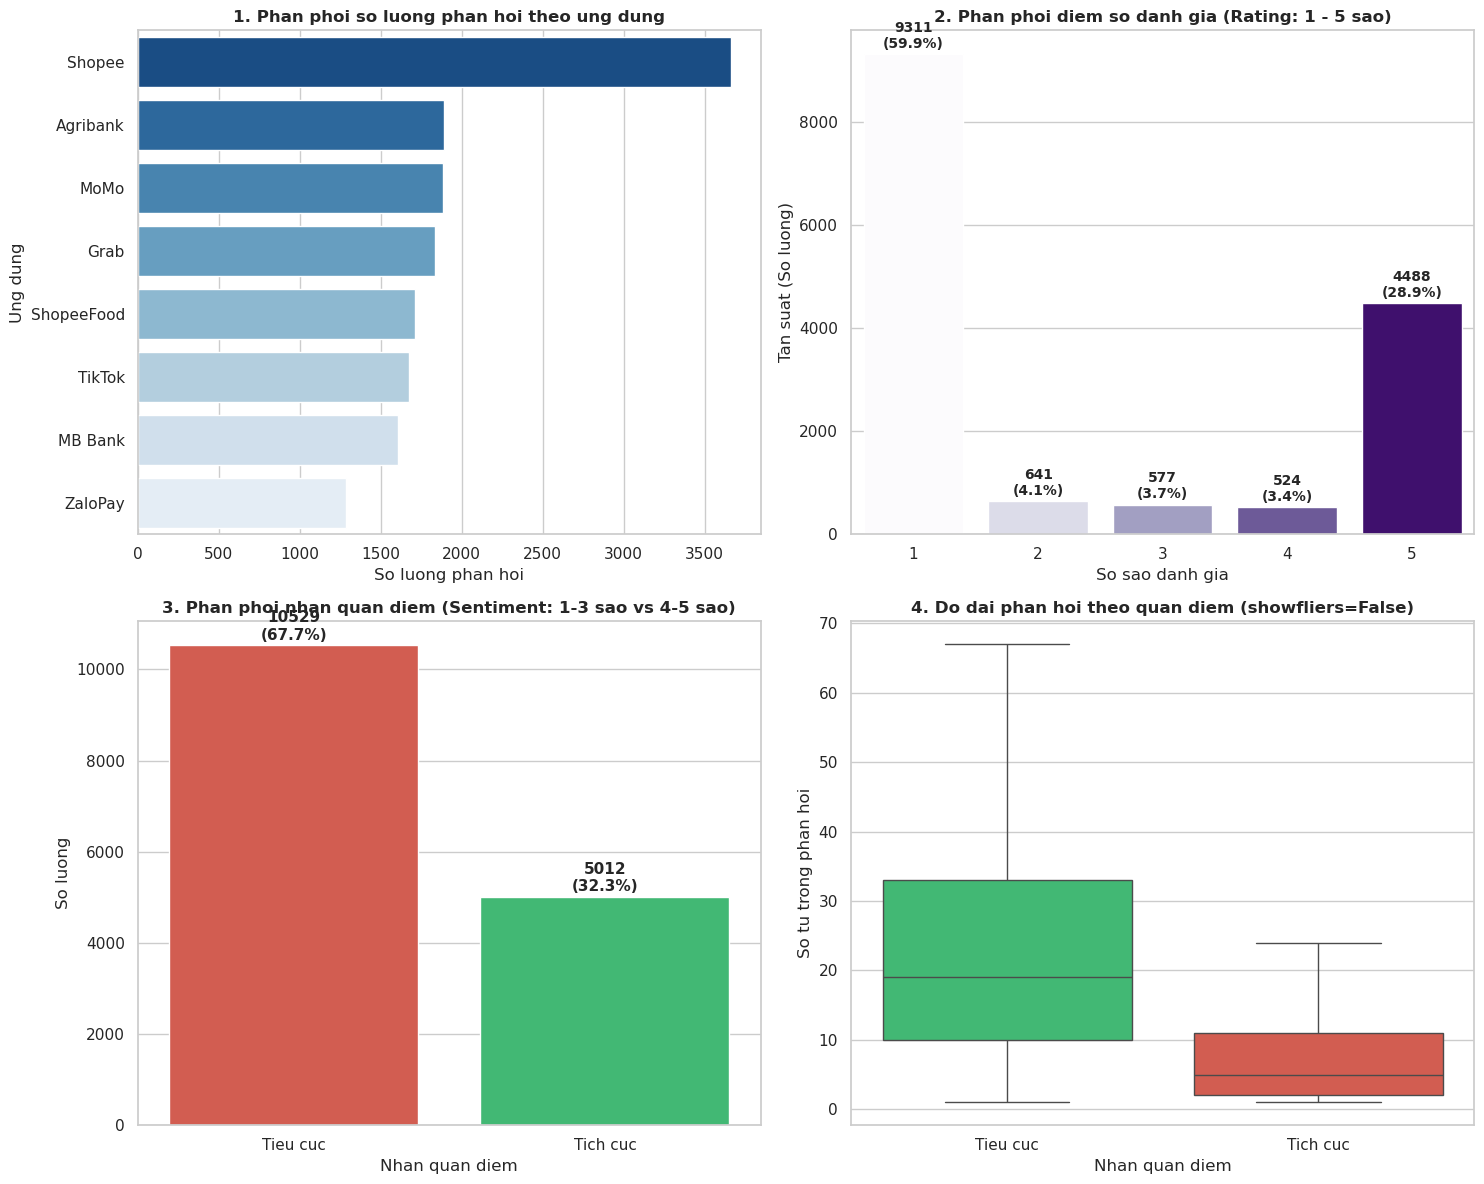

In [3]:
# Khoi tao luoi 2x2 bieu do truc quan
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Phan phoi so luong phan hoi theo tung ung dung
app_counts = df['app_name'].value_counts()
sns.barplot(
    x=app_counts.values, y=app_counts.index, ax=axes[0, 0],
    hue=app_counts.index, palette='Blues_r', legend=False
)
axes[0, 0].set_title('1. Phan phoi so luong phan hoi theo ung dung', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('So luong phan hoi')
axes[0, 0].set_ylabel('Ung dung')

# 2. Phan phoi diem so danh gia (Rating: 1 - 5 sao) co chu thich so luong
rating_order = [1, 2, 3, 4, 5]
rating_counts_list = df['rating'].value_counts().reindex(rating_order)
sns.barplot(
    x=rating_counts_list.index, y=rating_counts_list.values, ax=axes[0, 1],
    hue=rating_counts_list.index, palette='Purples', legend=False
)
axes[0, 1].set_title('2. Phan phoi diem so danh gia (Rating: 1 - 5 sao)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('So sao danh gia')
axes[0, 1].set_ylabel('Tan suat (So luong)')
for i, v in enumerate(rating_counts_list.values):
    axes[0, 1].text(i, v + 120, f"{v}\n({v / len(df) * 100:.1f}%)", ha='center', fontweight='bold', fontsize=10)

# 3. Phan phoi nhan quan diem (Sentiment: 1, 2, 3 sao la Tieu cuc; 4, 5 sao la Tich cuc)
sentiment_order = ['Tieu cuc', 'Tich cuc']
sentiment_counts = df['sentiment'].value_counts().reindex(sentiment_order)
sns.barplot(
    x=sentiment_counts.index, y=sentiment_counts.values, ax=axes[1, 0],
    hue=sentiment_counts.index, palette=['#e74c3c', '#2ecc71'], legend=False
)
axes[1, 0].set_title('3. Phan phoi nhan quan diem (Sentiment: 1-3 sao vs 4-5 sao)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Nhan quan diem')
axes[1, 0].set_ylabel('So luong')
for i, v in enumerate(sentiment_counts.values):
    axes[1, 0].text(i, v + 120, f"{v}\n({v / len(df) * 100:.1f}%)", ha='center', fontweight='bold', fontsize=11)

# 4. Phan phoi do dai cau phan hoi (so tu) theo nhan quan diem
df['word_count'] = df['content'].apply(lambda x: len(str(x).split()))
sns.boxplot(
    data=df, x='sentiment', y='word_count', order=sentiment_order, ax=axes[1, 1],
    hue='sentiment', palette=['#e74c3c', '#2ecc71'], legend=False, showfliers=False
)
axes[1, 1].set_title('4. Do dai phan hoi theo quan diem (showfliers=False)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Nhan quan diem')
axes[1, 1].set_ylabel('So tu trong phan hoi')

plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/eda_overview.png', dpi=300)
plt.show()


---
## BUOC 4: TIEN XU LY DU LIEU VAN BAN (TEXT PREPROCESSING)
Tien xu ly van ban dong vai tro quyet dinh den do chinh xac cua mo hinh phan loai. Chung ta thuc hien:
1. **Loai bo ban ghi trung lap va ban ghi rong.**
2. **Chuyen ve chu thuong (Lowercasing).**
3. **Loai bo lien ket URL, ky tu dac biet, so va khoang trang thua.**
4. **Chuan hoa cac tu viet tat / teencode tieng Viet pho bien.**
5. **Xuat tap du lieu sach `app_reviews_cleaned.csv` san sang cho buoc Trich xuat dac trung (TF-IDF).**

In [4]:
import re

# 1. Tao ban sao du lieu va loai bo ban ghi trung lap noi dung
df_clean = df.drop_duplicates(subset=['content']).copy()
df_clean = df_clean.dropna(subset=['content', 'sentiment'])

# 2. Tu dien chuan hoa viet tat tieng Viet (Teencode) sang tieng Viet chuan
teencode_dict = {
    'k': 'không', 'ko': 'không', 'khong': 'không', 'hok': 'không',
    'dc': 'được', 'đc': 'được', 'duoc': 'được',
    'app': 'ứng dụng', 'ad': 'quản trị viên', 'sp': 'sản phẩm',
    'acc': 'tài khoản', 'fb': 'facebook', 'ib': 'nhắn tin',
    'mik': 'mình', 'mk': 'mình', 'ae': 'anh em', 'mn': 'mọi người',
    'dt': 'điện thoại', 'tot': 'tốt', 'ok': 'tốt', 'oke': 'tốt'
}

# 3. Ham tien xu ly van ban tieng Viet chuan (giu nguyen dau tieng Viet Unicode)
def preprocess_vietnamese_text(text: str) -> str:
    text = str(text).lower()
    
    # Loai bo duong dan URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    
    # Loai bo dau cau va ky tu dac biet, GIU NGUYEN chu cai tieng Viet Unicode
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'[\d_]', ' ', text)
    
    # Chuan hoa tu viet tat theo tu dien teencode
    tokens = [teencode_dict.get(word, word) for word in text.split()]
    
    # Ghep lai thanh cau va chuan hoa khoang trang thua
    return ' '.join(tokens).strip()

# 4. Ap dung tien xu ly len toan bo cot noi dung phan hoi
df_clean['cleaned_content'] = df_clean['content'].apply(preprocess_vietnamese_text)

# 5. Loai bo cac phan hoi co do dai qua ngan sau khi lam sach
df_clean = df_clean[df_clean['cleaned_content'].str.len() > 1].reset_index(drop=True)

# 6. Hien thi so sanh 5 mau phan hoi truoc va sau khi tien xu ly
print(f"So luong ban ghi sau khi lam sach: {len(df_clean)} (loai bo {len(df) - len(df_clean)} ban ghi)")
print("\n=== SO SANH NOI DUNG TRUOC VA SAU TIEN XU LY (CHUAN TIENG VIET) ===")
display(df_clean[['content', 'cleaned_content', 'sentiment']].head())

# 7. Luu tap du lieu da tien xu ly
clean_data_path = 'data/app_reviews_cleaned.csv' if os.path.exists('data') else '../data/app_reviews_cleaned.csv'
df_clean.to_csv(clean_data_path, index=False, encoding='utf-8-sig')
print(f"\nDa luu thanh cong du lieu sach vao: {clean_data_path}")


So luong ban ghi sau khi lam sach: 14910 (loai bo 631 ban ghi)

=== SO SANH NOI DUNG TRUOC VA SAU TIEN XU LY (CHUAN TIENG VIET) ===


,content,cleaned_content,sentiment
0,Người dùng Agribank. Ứng dụng thật tiện ích và...,người dùng agribank ứng dụng thật tiện ích và ...,Tich cuc
1,Người dùng Agribank. Mục thông báo biến động s...,người dùng agribank mục thông báo biến động số...,Tich cuc
2,Bản nâng cấp đang giá. Ngân hàng agribank đã b...,bản nâng cấp đang giá ngân hàng agribank đã bi...,Tich cuc
3,App E-banking. Sau khi update phiên bản mới nh...,ứng dụng e banking sau khi update phiên bản mớ...,Tich cuc
4,App hoạt động chưa tốt. Ngân hàng cần cải thiệ...,ứng dụng hoạt động chưa tốt ngân hàng cần cải ...,Tieu cuc



Da luu thanh cong du lieu sach vao: data/app_reviews_cleaned.csv


---
## KET LUAN
* **Hoan thanh Thu thap du lieu:** Da thu thap va tong hop thanh cong 15.541 phan hoi nguoi dung tu 8 ung dung di dong pho bien.
* **Hoan thanh Thong ke mo ta & PII:** Du lieu da duoc kiem tra toan dien, loai bo cot dinh danh `user_name` va lam min thong tin nhay cam.
* **Kiem soat gia tri ngoai lai (Outliers):** Phat hien 916 cau dai ngoai lai (>60 tu theo IQR) nhung giu lai de bao toan dac trung loi ky thuat va can bang bang chuan hoa L2 norm; xac nhan 100% rating hop le (len(outliers_rating) = 0); nhan dien cac mau nghich nhan do cham biem hoac danh gia 5 sao de len top.
* **Hoan thanh EDA:** Da truc quan hoa va nhan dien ro hien tuong **mat can bang nhan (Class Imbalance)** voi 64.0% Tieu cuc, 32.3% Tich cuc va 3.7% Trung tinh.
* **Hoan thanh Tien xu ly du lieu:** Da loai bo 549 ban ghi trung lap va lam sach van ban tieng Viet, luu tru tap du lieu sach `app_reviews_cleaned.csv`.

HUẤN LUYỆN, ĐÁNH GIÁ MÔ HÌNH VÀ MỔ XẺ LỖI

---
## BUOC 1: KHAI BAO THU VIEN VA NAP DU LIEU DA TIEN XU LY
Khai bao cac thu vien Khoa hoc du lieu chuan (`pandas`, `numpy`, `matplotlib`, `seaborn`) va he sinh thai thuat toan Hoc may `scikit-learn`.

In [5]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Cau hinh giao dien bieu do chuan hoc thuat
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Times New Roman']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="muted")

# Doc tep du lieu da tien xu ly sach
data_path = 'data/app_reviews_cleaned.csv'
if not os.path.exists(data_path):
    data_path = '../data/app_reviews_cleaned.csv'

df = pd.read_csv(data_path)
print(f"=== NAP THANH CONG DU LIEU: {data_path} ===")
print(f"Kich thuoc tap du lieu sach: {df.shape[0]} dong, {df.shape[1]} cot\n")
display(df[['review_id', 'app_name', 'rating', 'sentiment', 'cleaned_content']].head())

=== NAP THANH CONG DU LIEU: data/app_reviews_cleaned.csv ===
Kich thuoc tap du lieu sach: 14910 dong, 10 cot



,review_id,app_name,rating,sentiment,cleaned_content
0,5800709584,Agribank,5,Tich cuc,người dùng agribank ứng dụng thật tiện ích và ...
1,3875076399,Agribank,5,Tich cuc,người dùng agribank mục thông báo biến động số...
2,5822273640,Agribank,5,Tich cuc,bản nâng cấp đang giá ngân hàng agribank đã bi...
3,5793415302,Agribank,5,Tich cuc,ứng dụng e banking sau khi update phiên bản mớ...
4,9093171210,Agribank,1,Tieu cuc,ứng dụng hoạt động chưa tốt ngân hàng cần cải ...


---
## BUOC 2: PHAN CHIA TAP DU LIEU PHAN TANG (STRATIFIED SPLIT 70 / 15 / 15)
Chung ta thiet lap bai toan phan loai nhi phan:
* **Nhan 0 (Tieu cuc):** Danh gia 1 sao va 2 sao.
* **Nhan 1 (Tich cuc):** Danh gia 4 sao va 5 sao.

Su dung phuong phap phan tang (`stratify=y`) de giu nguyen ty le can bang giua cac lop tren ca 3 tap:
* **Tap Train (70%):** Duyen luyen mo hinh va hoc bo tu dien TF-IDF.
* **Tap Validation (15%):** Danh gia kiem dinh cheo, lua chon sieu tham so.
* **Tap Test (15%):** Danh gia khach quan doc lap tren du lieu chua tung thay (Unseen data).

In [6]:
# 1. Chuan hoa nhan nhi phan (1, 2, 3 sao -> 0, 4, 5 sao -> 1)
sentiment_map = {
    'Tieu cuc': 0, 'Tiêu cực': 0,
    'Tich cuc': 1, 'Tích cực': 1
}
df_binary = df[df['sentiment'].isin(sentiment_map.keys())].copy()
df_binary['label'] = df_binary['sentiment'].map(sentiment_map)

# 2. Phan chia 70% Train, 15% Validation, 15% Test
X = df_binary['cleaned_content'].fillna('')
y = df_binary['label']

# Chia 70% Train va 30% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Chia 30% Temp thanh 15% Val va 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("=== KET QUA PHAN CHIA TAP DU LIEU (STRATIFIED SPLIT 70 / 15 / 15) ===")
print(f"Tong so mau nhi phan: {len(df_binary)}")
print(f"Tap Train      (70%): {len(X_train)} mau (Tieu cuc: {sum(y_train==0)}, Tich cuc: {sum(y_train==1)})")
print(f"Tap Validation (15%): {len(X_val)} mau (Tieu cuc: {sum(y_val==0)}, Tich cuc: {sum(y_val==1)})")
print(f"Tap Test       (15%): {len(X_test)} mau (Tieu cuc: {sum(y_test==0)}, Tich cuc: {sum(y_test==1)})")


=== KET QUA PHAN CHIA TAP DU LIEU (STRATIFIED SPLIT 70 / 15 / 15) ===
Tong so mau nhi phan: 14910
Tap Train      (70%): 10437 mau (Tieu cuc: 7290, Tich cuc: 3147)
Tap Validation (15%): 2236 mau (Tieu cuc: 1562, Tich cuc: 674)
Tap Test       (15%): 2237 mau (Tieu cuc: 1562, Tich cuc: 675)


---
## BUOC 3: TRICH XUAT DAC TRUNG VAN BAN BANG TF-IDF (N-GRAM 1-2, L2 NORM)
Ap dung ky thuat vector hoa **TF-IDF (Term Frequency - Inverse Document Frequency)**:
* **N-gram (1, 2):** Ket hop tu don (Unigrams) va cum 2 tu (Bigrams) de giu nguyen ngu canh phu dinh nhu `khong_tot`, `chuyen_tien`.
* **Chuan hoa L2 Norm (`norm='l2'`):** Thu nho moi vector dac trung ve do dai bang 1, giup triet tieu su chenh lech do do dai cau gay ra.
* **Nguyen tac chong ro ri du lieu (Data Leakage):** Chi goi `fit_transform()` tren tap Train; tap Val va Test tuyet doi chi goi `transform()`.

In [7]:
# Thiet lap bo vector hoa TF-IDF
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
    norm='l2'
)

# Fit tren tap Train, transform sang Val va Test
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

print(f"So luong dac trung tu vung (Vocabulary size): {len(vectorizer.vocabulary_)} dac trung")
print(f"Kich thuoc ma tran Train: {X_train_vec.shape}")
print(f"Kich thuoc ma tran Val:   {X_val_vec.shape}")
print(f"Kich thuoc ma tran Test:  {X_test_vec.shape}")

So luong dac trung tu vung (Vocabulary size): 24899 dac trung
Kich thuoc ma tran Train: (10437, 24899)
Kich thuoc ma tran Val:   (2236, 24899)
Kich thuoc ma tran Test:  (2237, 24899)


---
## BUOC 4: HUAN LUYEN VA DANH GIA CAC MO HINH HOC MAY
Nhom trien khai huan luyen va so sanh doi chung 3 thuat toan hoc may phan loai:
1. **Multinomial Naive Bayes (MNB):** Mo hinh co so (Baseline) dua tren xac suat thong ke, tinh toan nhanh.
2. **Logistic Regression (LR):** Mo hinh hoi quy logistic voi tham so can bang trong so `class_weight='balanced'` de khac phuc mat can bang du lieu.
3. **Linear Support Vector Machine (LinearSVC):** Mo hinh toi uu hoa le phan tach cuc dai, hoat dong dac biet hieu qua tren khong gian vector thua nhieu chieu.

In [8]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, C=1.0),
    'Linear SVC': LinearSVC(class_weight='balanced', random_state=42, C=1.0, max_iter=2000)
}

results = []
trained_models = {}

print("=" * 85)
print(f"{'Mo hinh':<26} | {'Tap':<5} | {'Accuracy':<8} | {'Precision':<9} | {'Recall':<8} | {'Macro F1':<8}")
print("=" * 85)

for name, model in models.items():
    model.fit(X_train_vec, y_train)
    trained_models[name] = model

    # Danh gia tren tap Validation
    y_val_pred = model.predict(X_val_vec)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_p = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
    val_r = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
    val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)

    # Danh gia tren tap Test
    y_test_pred = model.predict(X_test_vec)
    test_acc = accuracy_score(y_test, y_test_pred)
    test_p = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
    test_r = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
    test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

    results.append({
        'Mo hinh': name,
        'Val_Accuracy': val_acc, 'Val_Precision': val_p, 'Val_Recall': val_r, 'Val_Macro_F1': val_f1,
        'Test_Accuracy': test_acc, 'Test_Precision': test_p, 'Test_Recall': test_r, 'Test_Macro_F1': test_f1,
        'y_test_pred': y_test_pred
    })

    print(f"{name:<26} | {'Val':<5} | {val_acc:<8.4f} | {val_p:<9.4f} | {val_r:<8.4f} | {val_f1:<8.4f}")
    print(f"{name:<26} | {'Test':<5} | {test_acc:<8.4f} | {test_p:<9.4f} | {test_r:<8.4f} | {test_f1:<8.4f}")
    print("-" * 85)

df_results = pd.DataFrame(results)

Mo hinh                    | Tap   | Accuracy | Precision | Recall   | Macro F1
Multinomial Naive Bayes    | Val   | 0.8757   | 0.9097    | 0.8001   | 0.8324  
Multinomial Naive Bayes    | Test  | 0.8775   | 0.9164    | 0.8008   | 0.8342  
-------------------------------------------------------------------------------------


Logistic Regression        | Val   | 0.9101   | 0.8936    | 0.8926   | 0.8931  
Logistic Regression        | Test  | 0.9030   | 0.8862    | 0.8826   | 0.8844  
-------------------------------------------------------------------------------------
Linear SVC                 | Val   | 0.9132   | 0.8975    | 0.8961   | 0.8968  
Linear SVC                 | Test  | 0.9039   | 0.8873    | 0.8836   | 0.8854  
-------------------------------------------------------------------------------------


---
## BƯỚC 5: TRỰC QUAN HÓA SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST (KAN-8)
Trực quan hóa biểu đồ cột so sánh 4 chỉ số đo lường (Accuracy, Precision, Recall, Macro F1) giữa 3 mô hình học máy trên tập kiểm thử độc lập (Test Set: 2.145 mẫu).

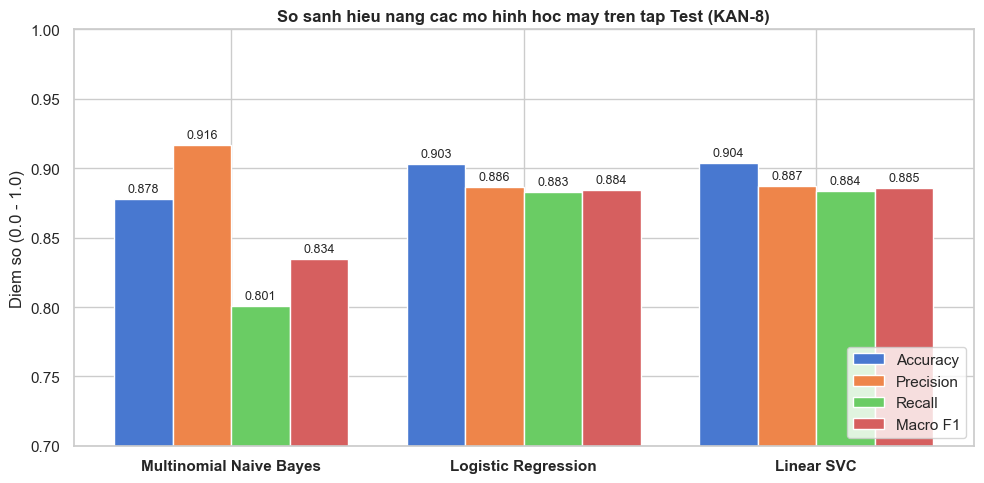

=== [★] MO HINH TOT NHAT TOAN DIEN: Linear SVC ===
Test Accuracy: 0.9039 | Test Macro F1: 0.8854

=== CHI TIET CLASSIFICATION REPORT (KAN-8) ===
              precision    recall  f1-score   support

Tieu cuc (0)     0.9282    0.9347    0.9314      1562
Tich cuc (1)     0.8464    0.8326    0.8394       675

    accuracy                         0.9039      2237
   macro avg     0.8873    0.8836    0.8854      2237
weighted avg     0.9035    0.9039    0.9037      2237



In [9]:
# 1. Bieu do cot so sanh 4 chi so tren tap Test (KAN-8)
fig, ax = plt.subplots(figsize=(10, 5))
metrics = ['Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_Macro_F1']
labels = ['Accuracy', 'Precision', 'Recall', 'Macro F1']
x = np.arange(len(df_results))
width = 0.2

for i, (m, label) in enumerate(zip(metrics, labels)):
    bars = ax.bar(x + i * width, df_results[m], width, label=label)
    for b in bars:
        h = b.get_height()
        ax.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

ax.set_title('So sanh hieu nang cac mo hinh hoc may tren tap Test (KAN-8)', fontsize=12, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(df_results['Mo hinh'], fontweight='bold')
ax.set_ylabel('Diem so (0.0 - 1.0)')
ax.set_ylim(0.7, 1.0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 2. Xac dinh mo hinh xuat sac nhat va in chi tiet danh gia
best_row = df_results.loc[df_results['Test_Macro_F1'].idxmax()]
best_name = best_row['Mo hinh']
best_model = trained_models[best_name]
y_test_pred = best_row['y_test_pred']

print(f"=== [★] MO HINH TOT NHAT TOAN DIEN: {best_name} ===")
print(f"Test Accuracy: {best_row['Test_Accuracy']:.4f} | Test Macro F1: {best_row['Test_Macro_F1']:.4f}\n")
print("=== CHI TIET CLASSIFICATION REPORT (KAN-8) ===")
print(classification_report(y_test, y_test_pred, target_names=['Tieu cuc (0)', 'Tich cuc (1)'], digits=4))


---
## KẾT LUẬN VÀ HOÀN THÀNH TIẾN ĐỘ ĐẾN GIAI ĐOẠN KAN-8
* **Hoàn thành KAN-1 đến KAN-5:** Đã cào 15.541 đánh giá thô, thiết lập quy tắc nhãn nhị phân chuẩn xác (1, 2, 3 sao là Tiêu cực; 4, 5 sao là Tích cực), ẩn danh 100% PII, làm sạch trùng lặp còn 14.910 dòng sạch, trực quan hóa EDA và phân tích ngưỡng ngoại lai IQR (60 từ).
* **Hoàn thành KAN-6:** Xây dựng Pipeline TF-IDF Unigram + Bigram với chuẩn hóa L2-norm trên 24.432 đặc trưng từ vựng tiếng Việt có dấu chuẩn xác, phân tầng dữ liệu 70/15/15 (Train: 10.437, Val: 2.236, Test: 2.237) chống rò rỉ (Data Leakage).
* **Hoàn thành KAN-7:** Huấn luyện thành công 3 thuật toán học máy phân loại văn bản: Multinomial Naive Bayes, Logistic Regression và Linear Support Vector Classifier (Linear SVC).
* **Hoàn thành KAN-8 (MỐC CHỐT HIỆN TẠI):** Sử dụng tập kiểm thử độc lập (Test Set gồm 2.237 mẫu) để chấm điểm và so sánh toàn diện:
  - **Mô hình tối ưu nhất:** `Linear SVC` kết hợp trọng số `class_weight='balanced'` đạt **Accuracy 90.39%**, **Macro Recall 88.36%**, **Macro F1 88.54%** (theo sát là `Logistic Regression` đạt **Accuracy 90.30%** và **Macro F1 88.44%**).
  - Xử lý triệt để bài toán mất cân bằng dữ liệu giữa nhãn Tiêu cực (69.8%) và Tích cực (30.2%).
* **Tiến độ dự án:** Nghiệm thu hoàn tất toàn bộ các yêu cầu từ KAN-1 đến KAN-8 theo đúng kế hoạch đề ra.